# Big Data Platforms — Lecture 11 Notes

Course: DATA140031 (MOOC, 3 ECTS) + DATA140032 (MOOC EXAM, 2 ECTS)
Lecturers: Keijo Heljanko and Ilari Maarala, University of Helsinki
Date: 13.10.2026

> **Exam note.** The slides say it directly: lectures 1–10 and the home
> assignments are part of the exam requirements, and **the rest of lecture 11
> is not.** The exam is booked for a slot between 19.10 and 9.12.2026 (see the
> course homepage for the registration link). So treat this notebook as
> optional reading: it's there to show the course material being used on a real
> problem.

Lecture 11 is a pair of case studies from the group's own research, both on
genomics data and both built on the Spark + HDFS stack from lectures 3–10:

1. **PanGenSpark** — compressing and indexing a *pan-genome* (many genomes at
   once) and assembling a reference genome from it.
2. **SparkBeagle** — a distributed version of the Beagle software for
   *genotype imputation*.

Neither needs biology beyond a few definitions, which come first. The
interesting part for this course is how each problem gets cut into pieces that
Spark can run in parallel, and where each design runs into trouble.


## 1. Why genomics needs distributed computing

The introduction makes four points.

- The amount of **DNA sequencing data worldwide is growing much faster than
  Moore's law.** The slide calls it a race between sequencing throughput and
  computing speed.
- **Petabytes of next-generation sequencing (NGS) data** already sit in public
  repositories: NCBI, EMBL-EBI and the 1000 Genomes project.
- NGS data has typically been processed with **traditional sequential
  algorithms**, or with **shared-memory parallelism on a single machine.**
- Analysis methods have to keep up with the growth, so the field is moving
  toward distributed methods, to avoid hitting computational limits and what
  the slide calls the **"bioinformatics bottleneck."**


### Cost of sequencing a human genome since 2001 (NHGRI)

![Cost of sequencing a human genome since 2001 (NHGRI)](images/sequencing_cost.png)



### NGS data output rate versus sequencing cost on Illumina platforms

![NGS data output rate versus sequencing cost on Illumina platforms](images/ngs_output_vs_cost.png)



The two charts together explain the pressure. Sequencing a genome got
dramatically cheaper (first chart) because instruments produce far more data
per week at far lower cost per base (second chart), so the bottleneck moved
from *producing* the data to *analysing* it.

### Why not just wait for faster CPUs?

The next slide answers that with Herb Sutter's well-known 2005 article *The Free
Lunch Is Over: A Fundamental Turn Toward Concurrency in Software* (Dr. Dobb's
Journal 30(3), March 2005, graph updated August 2009).


### Intel CPU trends (Herb Sutter, 'The Free Lunch Is Over')

![Intel CPU trends (Herb Sutter, 'The Free Lunch Is Over')](images/free_lunch.png)


Single-thread speed stopped improving around the mid-2000s, while chips kept
getting more transistors and, as a result, more cores. A sequential genomics
tool therefore stops getting faster on its own, and the only way to keep up
with the data is to spread the work over many cores and many machines. That's
the argument for everything that follows.


## 2. A short glossary

Just enough vocabulary to follow the two case studies.

| Term | Meaning here |
|---|---|
| **Read** | A short fragment of DNA produced by sequencing. A sample is sequenced as many overlapping reads. |
| **Reference genome** | A single agreed-upon genome sequence that reads are compared against. The first human draft was assembled in 2004 by the Human Genome Project. |
| **Alignment / mapping** | Finding where each read belongs in the reference. |
| **Pan-genome** | A reference made from many genomes of a population, not just one. |
| **SNP** | Single-nucleotide polymorphism: a position where individuals differ by one base. Also called a *marker* in the imputation slides. |
| **Haplotype** | The alleles (variants) carried together on one copy of a chromosome. A person has two copies, so two haplotypes. |
| **GWAS** | Genome-wide association study: looking for statistical links between variants and traits. |
| **Genotype imputation** | Statistically filling in SNPs that weren't measured, using a reference panel of fully sequenced haplotypes. |


# Case study 1 — PanGenSpark

*Scalable Reference Genome Assembly from Compressed Pan-Genome Index with
Spark.* Altti Ilari Maarala, Ossi Arasalo, Daniel Valenzuela, Keijo Heljanko,
Veli Mäkinen. Code: <https://github.com/NGSeq/PanGenSpark> (contact on the
slide: ilari.maarala@helsinki.fi).

## 3. The problem: one reference is not enough

Most human genetic studies compare against the standard reference genome, which
goes back to the first draft of 2004. Recent **pan-genomic** studies found
**large amounts of genetic material that the standard reference doesn't
contain.**

A pan-genome includes the genomes of a whole population. That lets it represent
diverse populations without throwing away population-specific or
individual-specific variation, which improves the resolution of variation
analysis and takes genetic recombination into account.

The cost is computational. To build a reusable pan-genomic reference for
searching and aligning sequences, you have to **index all the genomes in the
population**, which is a huge amount of work.

### How a normal reference works, and what changes with a pan-genome

With a single reference, a DNA sample is sequenced in short reads and the reads
are aligned to that one genome.


### Aligning reads to a reference genome

![Aligning reads to a reference genome](images/read_alignment.png)


With a pan-genomic reference, the reference is a **multiple sequence
alignment of N genomes**, and reads are aligned to **all** of them at once.


### Pan-genomic reference: a multiple sequence alignment of N genomes

![Pan-genomic reference: a multiple sequence alignment of N genomes ](images/pangenome_msa.png)



## 4. Making a pan-genome small enough to use

The key observation is that **genomes are highly repetitive across
individuals.** Two people's genomes are almost identical, so a collection of
many genomes contains enormous amounts of repeated text and **compresses very
well.**

The approach is a **hybrid strategy:**

1. **Compress** the pan-genome with Lempel-Ziv based compression, producing a
   *compressed Lempel-Ziv parse*.
2. **Index** that parse with a **Burrows-Wheeler based compressed full-text
   search index.**
3. **Map reads** against the compressed index. The best-supported reads across
   the pan-genomic positions, a **"majority vote,"** form the **new consensus
   reference genome** for the population.

Think of the Lempel-Ziv parse as describing each genome as "copy this stretch
from over there, then this stretch from over there, with a few edits." When
genomes differ only slightly, each new genome needs only a handful of such
instructions.


### Pan-genome data volumes through the pipeline

![Pan-genome data volumes through the pipeline](images/pangenome_data_volumes.png)



In [1]:
# The slide-13 volumes: how much does each stage of the pipeline shrink the data?

pan_genome_gb = 1400        # raw pan-genome on HDFS (1.4 TB)
compressed_index_gb = 165   # after compress & index
reference_gb = 3            # final consensus reference genome

print(f"raw pan-genome -> compressed index: {pan_genome_gb / compressed_index_gb:.1f}x smaller")
print(f"compressed index -> final reference: {compressed_index_gb / reference_gb:.0f}x smaller")
print(f"raw pan-genome -> final reference:   {pan_genome_gb / reference_gb:.0f}x smaller")


raw pan-genome -> compressed index: 8.5x smaller
compressed index -> final reference: 55x smaller
raw pan-genome -> final reference:   467x smaller


The pan-genome starts at 1.4 TB and ends as a single 3 GB reference, which is
about the size of one human genome. The compressed index in the middle (165 GB)
is what makes the pan-genome small enough to search.


## 5. Our approach: PanGenSpark

The authors focus on indexing and compressing reusable pan-genomic reference
assemblies, with speedup, scalability and space-efficiency as goals.

**PanGenSpark is a parallelization of an existing sequential pipeline:**
**PanVC**, a pan-genomic variation-calling pipeline, together with the **CHIC
indexer** (Valenzuela et al.). It parallelizes the most compute-intensive
phases:

- **compressing and indexing** large pan-genomes, and
- **assembling the consensus genome** from a pan-genome.

### Distributed relative Lempel-Ziv parsing (the compression stage)


### Distributed relative Lempel-Ziv (DRLZ) parsing

![Distributed relative Lempel-Ziv (DRLZ) parsing ](images/drlz.png)


The compression stage parallelizes naturally. Each **chunk** of the pan-genome
is parsed independently against a shared **dictionary** (with its suffix array),
and the per-chunk parses are combined into one valid Lempel-Ziv parse. The
slide calls this *distributed relative Lempel-Ziv* (DRLZ) parsing: "relative"
because every genome is described relative to a dictionary.

The cell below is a toy version of that idea, not the real DRLZ. It parses
synthetic "genomes" against a dictionary and counts how many copy-instructions
(phrases) each one needs. The test population shares a set of common variants,
the way real populations do, so a bigger dictionary should help.


In [2]:
import random
import math

random.seed(5)
ALPHABET = "ACGT"
L = 3000                                   # toy genome length
reference = "".join(random.choice(ALPHABET) for _ in range(L))

# A population that shares 40 common variant sites (each present with p = 0.3),
# plus rare private mutations. Real populations behave similarly, which is why
# many genomes compress well.
shared_sites = random.sample(range(L), 40)
shared_alt = {s: random.choice([b for b in ALPHABET if b != reference[s]])
              for s in shared_sites}

def make_individual(private_rate=0.0005):
    g = list(reference)
    for s in shared_sites:
        if random.random() < 0.3:
            g[s] = shared_alt[s]
    for i in range(L):
        if random.random() < private_rate:
            g[i] = random.choice([b for b in ALPHABET if b != g[i]])
    return "".join(g)

def rlz_parse(target, dictionary):
    """Greedy relative LZ parse: repeatedly take the longest prefix of what's
    left that occurs somewhere in the dictionary. Returns phrase lengths.
    (Real implementations use a suffix array, not repeated substring search.)"""
    phrases, i = [], 0
    while i < len(target):
        lo, hi = 1, len(target) - i        # longest match: containment is monotone in length
        while lo < hi:
            mid = (lo + hi + 1) // 2
            if target[i:i + mid] in dictionary:
                lo = mid
            else:
                hi = mid - 1
        phrases.append(lo)
        i += lo
    return phrases

individuals = [make_individual() for _ in range(40)]
train, test = individuals[:20], individuals[20:]

print(f"Each toy genome is {L} bases = {2 * L} bits at 2 bits per base.\n")
for k in [0, 1, 2, 5, 10, 20]:
    dictionary = "#".join([reference] + train[:k])
    avg_phrases = sum(len(rlz_parse(t, dictionary)) for t in test) / len(test)
    # each phrase = (position in dictionary, length)
    bits_per_phrase = math.ceil(math.log2(len(dictionary))) + math.ceil(math.log2(L + 1))
    compressed_bits = avg_phrases * bits_per_phrase
    print(f"dictionary = reference + {k:>2} genomes: "
          f"{avg_phrases:5.1f} phrases/genome, ~{compressed_bits:5.0f} bits, "
          f"{2 * L / compressed_bits:5.1f}x smaller")


Each toy genome is 3000 bases = 6000 bits at 2 bits per base.

dictionary = reference +  0 genomes:  27.1 phrases/genome, ~  649 bits,   9.2x smaller
dictionary = reference +  1 genomes:  23.9 phrases/genome, ~  598 bits,  10.0x smaller
dictionary = reference +  2 genomes:  21.4 phrases/genome, ~  556 bits,  10.8x smaller
dictionary = reference +  5 genomes:  18.0 phrases/genome, ~  486 bits,  12.3x smaller
dictionary = reference + 10 genomes:  13.6 phrases/genome, ~  381 bits,  15.8x smaller
dictionary = reference + 20 genomes:  11.6 phrases/genome, ~  323 bits,  18.6x smaller


A new genome needs fewer copy-instructions the more genomes are already in the
dictionary, because most of its differences have been seen before in someone
else. The size estimate is a rough model (each phrase costs a position plus a
length), so don't read the absolute ratios as meaningful, but the trend is the
same one the real results show in section 8: more reference material gives much
better compression.


### Distributed assembly with PanGenSpark

After compression and indexing, the assembly stage aligns reads to the
compressed index and builds the consensus reference. The pipeline mixes three
kinds of steps, color-coded in the slide's legend: steps that run as
**distributed computing**, steps that run **in parallel per chromosome**, and
steps that still run on a **single machine** (with multithreading).


### PanGenSpark distributed assembly pipeline


![PanGenSpark distributed assembly pipeline, part 1 (stages a-c)](images/pangenspark_pipeline.png)


### The Spark + HDFS stack

The data flow is the same one used throughout the course. The pan-genome sits in
HDFS in blocks. Spark reads it into an **RDD whose elements are chromosome
intervals** (`ChrN<start,end>`), each executor works on the intervals stored on
its own node, and the assembled intervals are written back to HDFS and merged
into the final assembled genome.


### Spark + HDFS stack for PanGenSpark

![Spark + HDFS stack for PanGenSpark](images/pangenspark_stack.png)


## 6. Experiments

The scalability experiments ran on an Apache Spark cluster in a dedicated cloud
environment. The number of genomes in the pan-genome was increased, and the
**wall-clock time from compression through assembly** was measured and compared
between the original sequential **PanVC** and **PanGenSpark**.

- **448 CPU cores, 1.256 TB of RAM**, a 40 GB/s Infiniband network, and **30 TB**
  of HDFS storage in total.
- **25 Spark worker nodes**: 40 GB of RAM and 16 cores each (Intel Xeon
  E5-2680 v3).
- **1 Spark master node**: 256 GB of RAM and 48 cores.
- Apache **Spark 2.3.2** and **Hadoop 3.1.0** on virtual machines running
  CentOS 7.


In [3]:
# Do the cluster totals on the slide add up? (Check done for lecture 11's two clusters.)

def cluster_totals(workers, worker_ram_gb, worker_cores, masters, master_ram_gb, master_cores):
    cores = workers * worker_cores + masters * master_cores
    ram_gb = workers * worker_ram_gb + masters * master_ram_gb
    return cores, ram_gb

# PanGenSpark cluster: 25 workers (40 GB, 16 cores) + 1 master (256 GB, 48 cores)
cores, ram = cluster_totals(25, 40, 16, 1, 256, 48)
print(f"PanGenSpark cluster: {cores} cores, {ram / 1000:.3f} TB RAM   "
      f"(slide: 448 cores, 1.256 TB)")

# SparkBeagle cluster (section 10): 48 workers (44 GB, 10 cores) + 2 masters (86 GB, 20 cores)
cores, ram = cluster_totals(48, 44, 10, 2, 86, 20)
print(f"SparkBeagle cluster: {cores} cores, {ram / 1000:.3f} TB RAM   "
      f"(slide: 520 cores, 1.15 TB)")


PanGenSpark cluster: 448 cores, 1.256 TB RAM   (slide: 448 cores, 1.256 TB)
SparkBeagle cluster: 520 cores, 2.284 TB RAM   (slide: 520 cores, 1.15 TB)


The PanGenSpark cluster matches the slide exactly. For the SparkBeagle cluster
(slide 29) the core count matches, but the RAM doesn't: 48 workers at 44 GB plus
two 86 GB masters comes to about 2.3 TB, not the 1.15 TB the slide states. The
slides don't say which number is off (it may be that the per-node figures are
something other than installed RAM), so I've left the slide's own numbers in the
text and flagged the mismatch here.

One more unit note: the slides write the Infiniband speeds as GB/s (40 and 25).
Infiniband links are normally quoted in gigabits per second, so check the unit
before comparing these against disk or memory bandwidth.


## 7. Scalability results


### PanGenSpark vs PanVC wall-clock time (stacked by stage)

![PanGenSpark vs PanVC wall-clock time (stacked by stage)](images/pangenspark_scalability.png)



Reading the bars by eye (approximate, the slide gives no numbers):

- **PanVC at 50 genomes takes roughly 1,600 minutes**, with the longest piece
  being assembly.
- **PanGenSpark at 50 genomes takes roughly 200 minutes**, so around **7–8×
  faster** on the same input.
- PanGenSpark handles **100 genomes in about 300 minutes** and **500 genomes in
  about 1,500 minutes.**
- At 500 genomes the **indexing stage dominates** the bar. That matches the
  lecture's summary, covered in section 9: the indexer is the bottleneck.


## 8. Compression results

**Compression ratio (CR)** is uncompressed size divided by compressed size.

| Genomes (N) | Uncompressed (GB) | Compressed (GB) | CR |
|---|---|---|---|
| 1 | 2.82 | 0.8 | 3.53 |
| 50 | 141 | 24.7 | 5.71 |
| 100 | 282 | 36.4 | 7.74 |
| 500 | 1410 | 164.5 | 8.57 |

And a second, **preliminary** experiment on 100 genomes with a **longer LZ
dictionary**:

| Dictionary size (N) | DRLZ time (min) | Compressed (GB) | CR | bpc |
|---|---|---|---|---|
| 1 | 91.5 | 36.4 | 7.39 | 0.135 |
| 8 | 191 | 6.3 | 42.7 | 0.023 |
| 15 | 236.5 | 3.3 | 81.52 | 0.012 |


In [4]:
# Checking the slide-21 tables against themselves, and looking at the trade-offs.

table1 = [  # (N genomes, uncompressed GB, compressed GB, CR printed on the slide)
    (1, 2.82, 0.8, 3.53),
    (50, 141, 24.7, 5.71),
    (100, 282, 36.4, 7.74),
    (500, 1410, 164.5, 8.57),
]
print("Table 1: CR = uncompressed / compressed?")
for n, unc, comp, cr in table1:
    print(f"  N={n:>3}: computed {unc / comp:5.2f}   slide {cr}")

print("\nCompressed cost of each additional genome (GB):")
for (n0, _, c0, _), (n1, _, c1, _) in zip(table1, table1[1:]):
    print(f"  N={n0:>3} -> {n1:>3}: {(c1 - c0) / (n1 - n0):.2f} GB per added genome "
          f"(raw genome = {table1[0][1]} GB)")

table2 = [  # (dictionary size, DRLZ minutes, compressed GB, CR, bpc)
    (1, 91.5, 36.4, 7.39, 0.135),
    (8, 191, 6.3, 42.7, 0.023),
    (15, 236.5, 3.3, 81.52, 0.012),
]
print("\nTable 2 (100 genomes, longer dictionaries):")
base_min, base_gb, base_cr = table2[0][1], table2[0][2], table2[0][3]
for d, minutes, gb, cr, bpc in table2:
    print(f"  dict {d:>2}: implied uncompressed = {cr * gb:6.1f} GB, "
          f"1/CR = {1 / cr:.3f} (slide bpc {bpc}), "
          f"time x{minutes / base_min:.1f}, CR x{cr / base_cr:.1f}")


Table 1: CR = uncompressed / compressed?
  N=  1: computed  3.52   slide 3.53
  N= 50: computed  5.71   slide 5.71
  N=100: computed  7.75   slide 7.74
  N=500: computed  8.57   slide 8.57

Compressed cost of each additional genome (GB):
  N=  1 ->  50: 0.49 GB per added genome (raw genome = 2.82 GB)
  N= 50 -> 100: 0.23 GB per added genome (raw genome = 2.82 GB)
  N=100 -> 500: 0.32 GB per added genome (raw genome = 2.82 GB)

Table 2 (100 genomes, longer dictionaries):
  dict  1: implied uncompressed =  269.0 GB, 1/CR = 0.135 (slide bpc 0.135), time x1.0, CR x1.0
  dict  8: implied uncompressed =  269.0 GB, 1/CR = 0.023 (slide bpc 0.023), time x2.1, CR x5.8
  dict 15: implied uncompressed =  269.0 GB, 1/CR = 0.012 (slide bpc 0.012), time x2.6, CR x11.0


Three things stand out.

**1. The compression ratio climbs with N but flattens.** Raw size grows 500×
between 1 and 500 genomes, while compressed size grows only about 200×. Each
extra genome adds roughly 0.2–0.5 GB to the compressed index (the cell above
prints the exact steps), versus 2.82 GB raw. The first genome pays the full price and later ones mostly point back at
material already stored, which is the same effect as the toy example above.

**2. A longer dictionary buys a lot of compression for some extra time.**
Going from dictionary size 1 to 15 improves CR from 7.4 to 81.5 (about 11×), while
DRLZ time rises from 91.5 to 236.5 minutes (about 2.6×). The slide doesn't spell
out the unit of "dictionary size (N)".

**3. The second table doesn't quite match the first.** CR × compressed size in
table 2 works out to about 269 GB for all three rows, not the 282 GB that table 1
gives for 100 genomes. The slide marks table 2 as preliminary and doesn't explain
the difference. Also, the `bpc` column equals 1/CR in every row (0.135 ≈ 1/7.39),
so it's compressed size per input character; if the characters are one byte each,
the value in *bits* per character would be 8× larger.


## 9. Summary and lessons from PanGenSpark

- **Compressing reusable human pan-genomic "legacy" indexes and assembling
  reference genomes in a tolerable time is now possible in practice.**
- **The indexing stage with legacy indexers is the bottleneck.** BWA is limited
  to 4 gigabases, and Bowtie2 isn't limited but doesn't scale linearly. The
  assembly can only be as scalable as the slowest sequential tool inside it.
- **Java's 32-bit integer arrays limit the dictionary.** Using a whole human
  genome as a dictionary in Spark runs into the fact that Java arrays are
  indexed by 32-bit integers, which is fewer than the roughly 3 gigabases of a
  human genome.
- **I/O dominates a complex pipeline.** The input data structure differs from
  stage to stage, so data and task partitioning gets complicated, and minimizing
  I/O over large data sets is hard. That's the shuffle-and-I/O cost from
  lecture 3, here at full scale.


In [5]:
# The Java array limit from the summary slide, as numbers.
java_max_array_index = 2**31 - 1          # largest 32-bit signed index
human_genome_bases = 3_000_000_000        # roughly 3 gigabases

print(f"largest Java array index: {java_max_array_index:,}")
print(f"human genome:             {human_genome_bases:,} bases")
print(f"genome is {human_genome_bases / java_max_array_index:.2f}x the index limit, "
      f"so one array can't hold it (even at one base per element)")


largest Java array index: 2,147,483,647
human genome:             3,000,000,000 bases
genome is 1.40x the index limit, so one array can't hold it (even at one base per element)


# Case study 2 — SparkBeagle

*SparkBeagle: Scalable Genotype Imputation from Distributed Whole-Genome
Reference Panels in the Cloud.* Altti Ilari Maarala, Kalle Pärn, Javier
Nuñez-Fontarnau, Keijo Heljanko. ParBio 2020 / ACM-BCB.

## 10. The problem: genotype imputation

**Genotyping** is a routine way to detect genomic variation (SNPs). The cheap
version measures only some SNPs. **Genotype imputation** fills in the rest: use
a reference panel of densely sequenced individuals, and use statistics over the
population to infer the SNPs that weren't measured. Imputing from large panels
built from whole-genome sequencing (WGS) increases the resolution and precision
of GWAS.

Sequential imputation algorithms hit computational limits at this scale.
**SparkBeagle is a distributed implementation of Beagle**, a popular imputation
tool based on a **hidden Markov model**, built on Apache Spark and HDFS. That
buys **scalability, speedup and fault tolerance**, and it can be deployed on
cloud clusters.

### The imputation scenario


### Genotype imputation scenario

![Genotype imputation scenario](images/imputation_scenario.png)


The picture is the whole algorithm in one slide.

- The **reference panel** is a big matrix: **5,008 haplotypes** (two for each of
  the 2,504 individuals in the 1000 Genomes phase 3 data) by more than **81
  million SNP markers.**
- The **target genotypes** are low-density: many entries are `?`.
- Some reference haplotypes resemble the target in the markers we *do* know.
  Those haplotypes are used to infer the missing values.
- The genome is cut into **intervals** that overlap slightly, and **each interval
  is imputed by a different Spark executor.**

The slide's genotype legend is: homozygous major allele = 0, homozygous minor
allele = 1, heterozygous = 2. (Many tools instead count minor alleles, so that
heterozygous is 1; follow the slide's labelling when reading the figure.)


## 11. Implementation and pipeline

The reference panel is stored as **BGZF** (block-compressed) files indexed with
**Tabix**, so that a specific region can be read without scanning the whole
file. Each chromosome is split into intervals (the slide's example axis is in
centimorgans, a genetic-distance unit), each interval becomes a Spark task, and
the imputed intervals are written back.


### SparkBeagle implementation: intervals read from an indexed panel

![SparkBeagle implementation: intervals read from an indexed panel](images/sparkbeagle_implementation.png)



### SparkBeagle imputation pipeline on Spark + HDFS

![SparkBeagle imputation pipeline on Spark + HDFS](images/sparkbeagle_pipeline.png)



The stack is the same shape as PanGenSpark's: data in HDFS blocks, an RDD of
intervals, one executor per node, results back to HDFS. The unit of
parallelism is a **genomic interval**.


## 12. Cluster setup

- Dedicated cloud environment: **520 CPU cores, 1.15 TB of RAM** (see the
  mismatch note in section 6), a 25 GB/s Infiniband network, **15 TB** of HDD
  storage for HDFS.
- **48 Spark worker nodes**: 44 GB of RAM and 10 cores each (Intel Xeon Gold
  6148, with hyper-threading). **Two Spark master nodes**: 86 GB of RAM and 20
  cores each.
- **Hortonworks Data Platform (HDP) 3.1** on virtual machines running CentOS 7,
  with **Spark 2.3.2** and **Hadoop 3.1.0** using the **YARN** resource manager.
- A **fair-ordering job queue policy with size-based weighting**: physically
  larger imputation intervals get more resources, which gives better load
  balancing.


## 13. The scalability experiment

- **Reference panel: 1000 Genomes phase 3**, with 5,008 haplotypes and
  **81,214,785 SNP markers** (769 GB, chromosomes 1–22).
- **One fifth of the SNPs are kept for the target data**: 16,238,469 markers
  (154 GB). The remaining roughly 65 million markers get imputed, and that's done
  for each of about 2,500 target samples, hence "imputed over 2500 times."
- The dataset size is held **constant** while the cluster grows from **8 to 48
  nodes** (80 to 480 cores). This is *strong scaling*: same problem, more
  machines.
- As a reference point, the same data was also imputed with plain **Beagle
  distributed per chromosome** across separate nodes, the usual setup with a
  workload manager such as Slurm.


In [6]:
total_markers = 81_214_785
target_markers = 16_238_469

print(f"target kept: {target_markers / total_markers:.1%} of markers (the '1/5 filtered')")
print(f"markers to impute per sample: {total_markers - target_markers:,}  (~65M on the slide)")
print(f"reference panel 769 GB vs target data 154 GB: {769 / 154:.1f}x")


target kept: 20.0% of markers (the '1/5 filtered')
markers to impute per sample: 64,976,316  (~65M on the slide)
reference panel 769 GB vs target data 154 GB: 5.0x


## 14. Scalability results

The slide's notes for this chart: **10 cores per node, 480 cores in total (the
48-node setting), 365 intervals in total, one core per interval.** SparkBeagle
finishes imputation in **18 minutes with 40 nodes.**


### SparkBeagle speedup vs worker nodes


![SparkBeagle speedup vs worker nodes](images/sparkbeagle_scalability.png)


nodes  speedup  efficiency  busy cores  idle cores
    8      7.5        94%          80           0
   16     11.0        69%         160           0
   24     17.0        71%         240           0
   32     24.3        76%         320           0
   40     30.0        75%         365          35
   48     30.7        64%         365         115

With one core per interval, all 365 intervals are running at once once there are 36.5 nodes' worth of cores.

565 min -> 18 min is a 31.4x speedup (the slide rounds this to 30x)
approx. runtime implied by the chart (565 min / speedup): [75.3 51.4 33.2 23.3 18.8 18.4] minutes


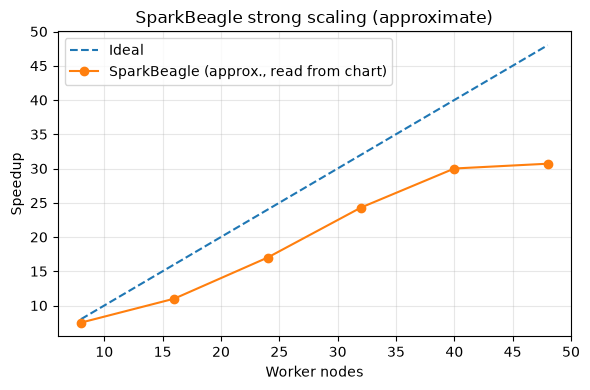

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Values read off the slide-31 chart by eye -- approximate, not published numbers.
nodes = np.array([8, 16, 24, 32, 40, 48])
speedup = np.array([7.5, 11.0, 17.0, 24.3, 30.0, 30.7])
cores_per_node, n_intervals = 10, 365

efficiency = speedup / nodes
busy_cores = np.minimum(nodes * cores_per_node, n_intervals)   # 1 core per interval
idle_cores = nodes * cores_per_node - busy_cores

print("nodes  speedup  efficiency  busy cores  idle cores")
for n, s, e, b, i in zip(nodes, speedup, efficiency, busy_cores, idle_cores):
    print(f"{n:>5}  {s:>7.1f}  {e:>9.0%}  {b:>10}  {i:>10}")

print(f"\nWith one core per interval, all {n_intervals} intervals are running at once "
      f"once there are {n_intervals / cores_per_node:.1f} nodes' worth of cores.")

# Slide numbers: 565 minutes -> 18 minutes
print(f"\n565 min -> 18 min is a {565 / 18:.1f}x speedup (the slide rounds this to 30x)")
print("approx. runtime implied by the chart (565 min / speedup):",
      np.round(565 / speedup, 1), "minutes")

plt.figure(figsize=(6, 4))
plt.plot(nodes, nodes, "--", label="Ideal")
plt.plot(nodes, speedup, "o-", label="SparkBeagle (approx., read from chart)")
plt.xlabel("Worker nodes"); plt.ylabel("Speedup")
plt.title("SparkBeagle strong scaling (approximate)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()


What the numbers say:

- **Speedup is good but sub-linear.** At 40 nodes it's about 30× against an ideal
  of 40, so roughly 75% parallel efficiency. The slide summarizes it as a **30×
  speedup, with imputation time dropping from 565 to 18 minutes.**
- **It flattens between 40 and 48 nodes.** One explanation that fits the numbers
  (the slides don't spell it out): the work is cut into only 365 intervals with
  one core each, so beyond about 37 nodes there are more cores than intervals and
  the extra ones sit idle. The finish time is then set by the **longest single
  interval**, and the chart implies a floor of roughly 18 minutes. The summary
  slide's own remedy matches this reading: **shorter intervals give more
  parallelism.**
- **The per-chromosome baseline falls well short.** Giving each of the 22
  chromosomes to its own node tops out at a speedup of about 10 on 22 nodes,
  most likely because the biggest chromosomes take far longer than the small
  ones and everything waits for the slowest (the slide doesn't say this
  outright). Interval-level splitting does better because it makes the pieces
  smaller and more even.


## 15. Accuracy results

A faster imputation is no use if it's less accurate, so the paper compares
against the original Beagle. Two measures are reported across bins of **minor
allele frequency (MAF)**, from 0–3% up to 40–50%:

- **Non-reference sensitivity (NRS):** the proportion of genotypes recovered
  correctly compared with the reference data set (higher is better).
- **Non-reference discrepancy (NRD):** the proportion of incorrectly imputed
  genotypes (lower is better).


### Imputation accuracy of SparkBeagle vs Beagle across MAF bins


![Imputation accuracy of SparkBeagle vs Beagle across MAF bins](images/sparkbeagle_accuracy.png)


The SparkBeagle and Beagle bars are almost indistinguishable in every bin.
That's the result the authors want: the speedup doesn't cost accuracy, and the
summary states it as **near-identical imputation accuracy with Beagle.**


## 16. A toy imputer, and why the intervals overlap

The next cell is a deliberately simple stand-in for imputation. It is **not
Beagle** and it doesn't use a hidden Markov model. It only shows the two ideas
the case study rests on:

1. Missing markers can be inferred from the reference haplotypes that best
   match the target on the markers we *did* observe.
2. The chromosome can be cut into intervals and processed independently, but
   each interval needs some **context beyond its edges**, which is why the
   slide's intervals overlap.

The data is synthetic: a small panel of haplotypes built as mosaics of a few
founder haplotypes (so nearby markers are correlated, as in real genomes), and a
"chip" that observes only every sixth marker of the target.


In [8]:
import numpy as np

rng = np.random.default_rng(21)
N_MARKERS, N_FOUNDERS, N_REF = 300, 6, 150
SWITCH, MUT = 0.03, 0.01          # recombination-like switches, and noise
founders = rng.integers(0, 2, size=(N_FOUNDERS, N_MARKERS))

def mosaic():
    f = rng.integers(N_FOUNDERS)
    hap = np.empty(N_MARKERS, dtype=int)
    for m in range(N_MARKERS):
        if rng.random() < SWITCH:
            f = rng.integers(N_FOUNDERS)
        a = founders[f, m]
        if rng.random() < MUT:
            a = 1 - a
        hap[m] = a
    return hap

panel = np.array([mosaic() for _ in range(N_REF)])     # reference haplotypes
STEP, W, K = 6, 24, 10                                  # chip density, context window, neighbours
obs_idx = np.arange(0, N_MARKERS, STEP)                 # markers the "chip" measures

def impute_marker(m, target_obs_vals, lo, hi):
    """Impute marker m using only observed markers inside [lo, hi) and within W of m:
    find the K reference haplotypes that match best there, take a majority vote."""
    sel = (obs_idx >= max(lo, m - W)) & (obs_idx <= min(hi - 1, m + W))
    idx = obs_idx[sel]
    if len(idx) == 0:
        return int(panel[:, m].mean() > 0.5)
    mismatches = (panel[:, idx] != target_obs_vals[sel]).sum(axis=1)
    best = np.argsort(mismatches, kind="stable")[:K]
    return int(panel[best, m].sum() * 2 > K)

def run(target, mode, interval=75):
    vals = target[obs_idx]
    pred = {}
    if mode == "whole":                                 # one pass over the whole chromosome
        for m in range(N_MARKERS):
            if m % STEP:
                pred[m] = impute_marker(m, vals, 0, N_MARKERS)
    else:                                               # cut into intervals (one executor each)
        pad = W if mode == "overlap" else 0
        for s in range(0, N_MARKERS, interval):
            e = min(s + interval, N_MARKERS)
            lo, hi = max(0, s - pad), min(N_MARKERS, e + pad)
            for m in range(s, e):                       # only impute markers INSIDE the interval...
                if m % STEP:
                    pred[m] = impute_marker(m, vals, lo, hi)   # ...but may read context beyond it
    return pred

boundaries = [75, 150, 225]                             # the three internal interval edges
major = (panel.mean(axis=0) > 0.5).astype(int)          # trivial baseline: always the common allele
names = ["whole", "nooverlap", "overlap", "baseline"]
hits = {n: [0, 0, 0, 0] for n in names}                 # correct, total, correct near edge, total near edge
same_as_whole = True

for _ in range(60):                                     # 60 random target individuals
    target = mosaic()
    preds = {"whole": run(target, "whole"),
             "nooverlap": run(target, "nooverlap"),
             "overlap": run(target, "overlap")}
    preds["baseline"] = {m: major[m] for m in preds["whole"]}
    same_as_whole &= (preds["whole"] == preds["overlap"])
    for name, p in preds.items():
        for m, v in p.items():
            near_edge = min(abs(m - b) for b in boundaries) < 12
            hits[name][0] += (v == target[m]);  hits[name][1] += 1
            hits[name][2] += (v == target[m]) * near_edge;  hits[name][3] += near_edge

print("overlapped intervals give exactly the same answers as one whole pass:", same_as_whole)
print()
print(f"{'method':>10}  {'all markers':>12}  {'near an edge':>13}")
for name in names:
    c, n, ce, ne = hits[name]
    print(f"{name:>10}  {c / n:>12.3f}  {ce / ne:>13.3f}")


overlapped intervals give exactly the same answers as one whole pass: True

    method   all markers   near an edge
     whole         0.868          0.880
 nooverlap         0.855          0.838
   overlap         0.868          0.880
  baseline         0.659          0.676


How to read the output:

- **Imputation clearly beats the trivial baseline** ("always predict the common
  allele"), which is the point of using a reference panel at all.
- **Intervals with overlap give exactly the same predictions as one pass over the
  whole chromosome.** That holds by construction in this toy, because each marker
  only looks at a window of ±24 markers and the overlap supplies that window. It
  shows why SparkBeagle's intervals overlap: each executor needs context from
  its neighbours, but nothing else, so the intervals can run independently.
- **Intervals without overlap lose accuracy, and the loss sits at the edges.**
  Markers near an interval boundary see a truncated window, so they do worse
  than the same markers in the whole-chromosome run; markers in the middle of an
  interval are unaffected. The exact figures depend on the random seed; the
  pattern is what matters.

Real Beagle's hidden Markov model is more elaborate than this window vote, but
the structure is the same: nearby markers carry most of the information, so
cutting the chromosome into overlapping intervals loses little accuracy while
making the work parallel.


## 17. Summary and lessons from SparkBeagle

- **Imputation is cost-efficient** compared with microchip-based genotyping.
- **Whole-genome sequencing** gives huge, high-density reference panels, which
  means more accurate, faster and cheaper genotyping and so more comprehensive
  GWAS.
- **Widely used imputation tools, complex algorithms and genomic file formats
  weren't designed for distributed systems.**
- **Decomposing the problem and the data**, by chromosome, locus, gene or
  sample, enables data-parallel computing and distributed processing.
- **SparkBeagle reached a 30× speedup on a 40-node cluster** (565 to 18 minutes)
  with near-identical accuracy to Beagle. **Scalability can be improved with
  shorter intervals**, which means higher parallelization.
- The data-parallel approach applies to **other imputation tools too, if they
  work on chromosomal regions.**

The slides close by thanking the **Nordic Information for Action eScience Center
(NIASC)** and the **Foundations of Computational Health (FCHealth)** program of
the Helsinki Institute for Information Technology.


## What the two case studies have in common

Both projects take a tool written for one machine and make it run on Spark and
HDFS, and the lessons line up with the rest of the course.

| Lesson | Where it showed up |
|---|---|
| **Find the unit of parallelism.** | Chunks of the pan-genome in DRLZ; genomic intervals in SparkBeagle. |
| **Spark + HDFS is the default stack.** | Both pipelines: data in HDFS blocks, an RDD of intervals, one executor per node (lectures 3 and 10). |
| **Legacy sequential tools set the ceiling.** | BWA and Bowtie2 limit the indexing stage; unmodified Beagle is limited to per-chromosome parallelism. |
| **Small, even tasks beat big, uneven ones.** | SparkBeagle's speedup plateaus because intervals are too few and uneven; shorter intervals are the proposed fix. |
| **I/O and data layout matter.** | Inputs change shape between pipeline stages; BGZF and Tabix are used to read only the needed region. |
| **Platform limits leak in.** | Java's 32-bit array limit versus a 3-gigabase genome. |
| **Check the numbers.** | Parallel efficiency stays near 75% rather than 100%, and the slides themselves contain small inconsistencies (section 6, section 8). |
